RESPOSTA AO IMPULSO h[n] = p^n u[n]  (H(z) = 1/(1 - p z^-1))
    Polo    |p|   classificação   erro vs. p^n       h[10]      h[100]      h[599]    Σ|h| (600)  Σ h² (energia)
----------------------------------------------------------------------------------------------------------
     0.5   0.50         ESTÁVEL        0.0e+00   0.0009766   7.889e-31   4.82e-181             2          1.3333
     0.9   0.90         ESTÁVEL        6.9e-16      0.3487   2.656e-05   3.902e-28            10          5.2632
    0.99   0.99         ESTÁVEL        9.1e-16      0.9044       0.366    0.002429        99.759          50.251
    1.05   1.05        INSTÁVEL        1.0e-15       1.629       131.5   4.925e+12    1.0342e+14      2.6088e+26
(erro relativo a p^n; Σ|h| e energia crescem sem limite quando |p| >= 1)

EVOLUÇÃO TEMPORAL
    Polo    τ = ∓1/ln|p| (am.)   n p/ |h|<1%   n p/ |h|<0,1%    n p/ |h|>1e3   dobra a cada (am.)
-----------------------------------------------------------------------------

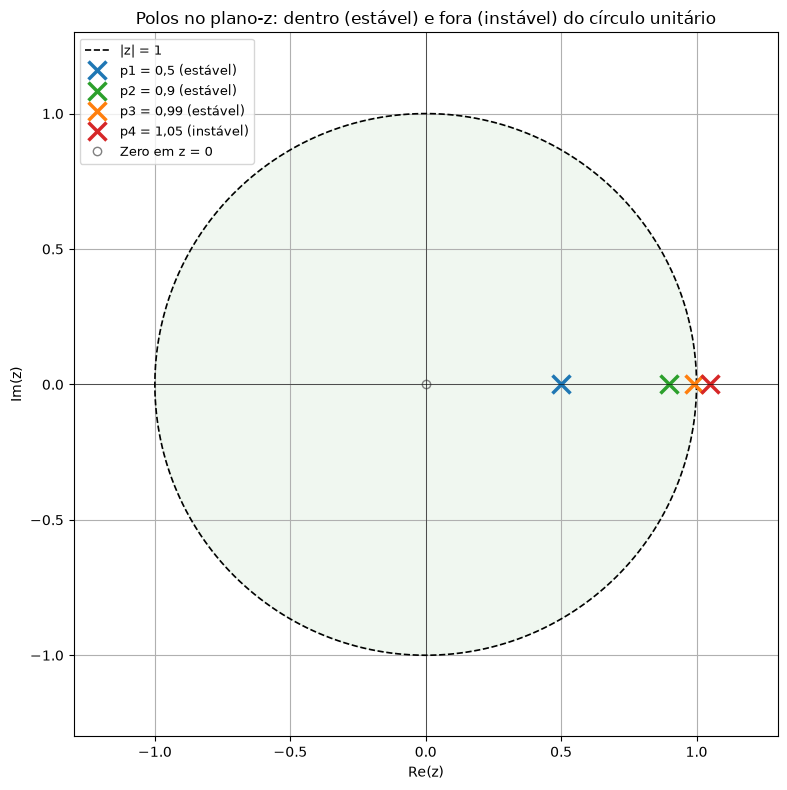

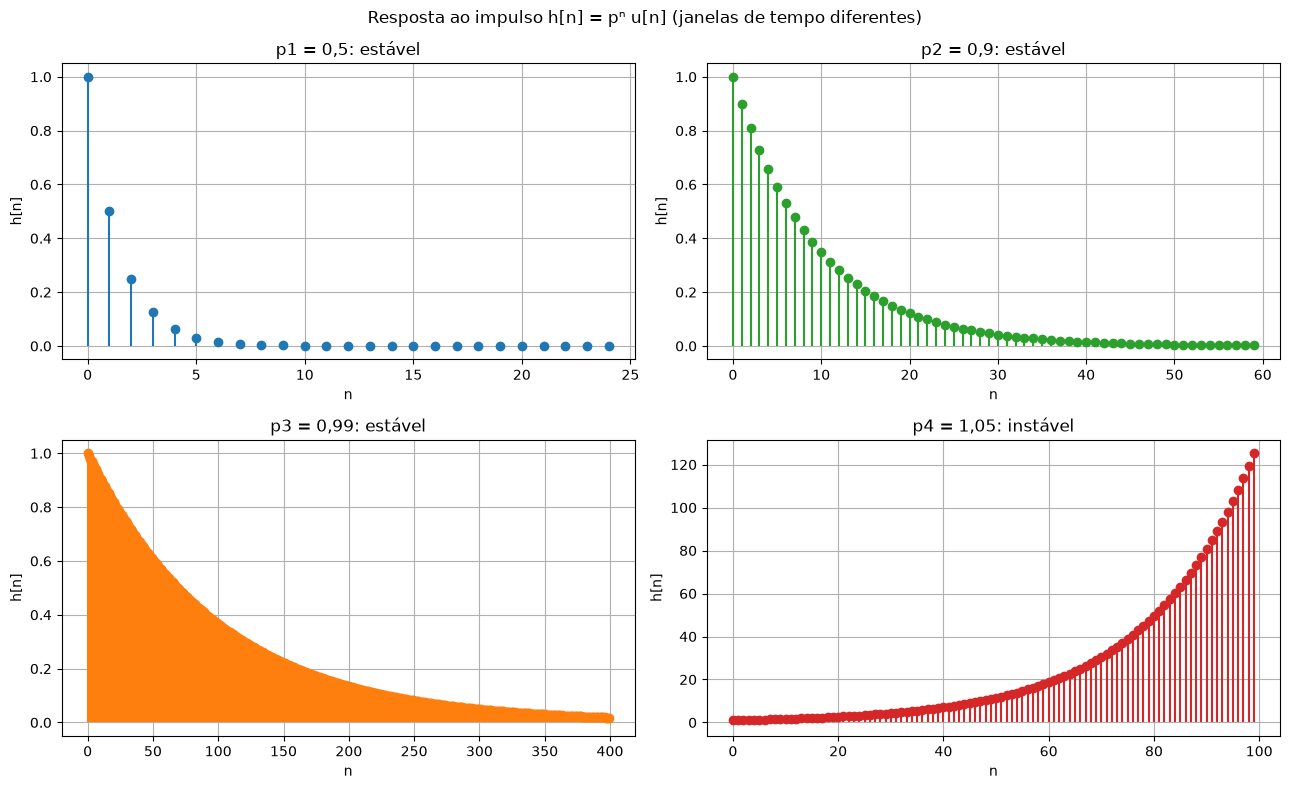

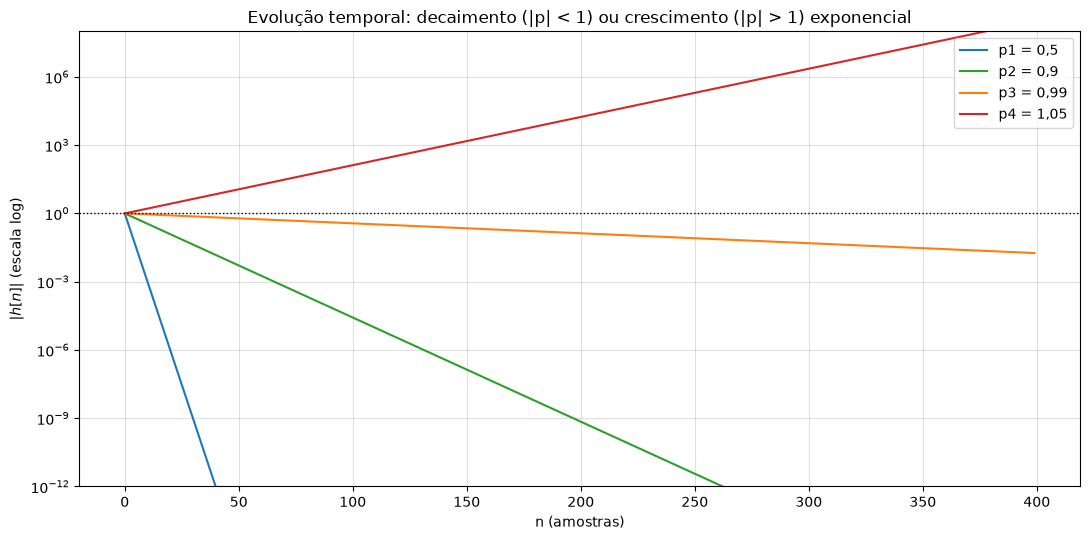

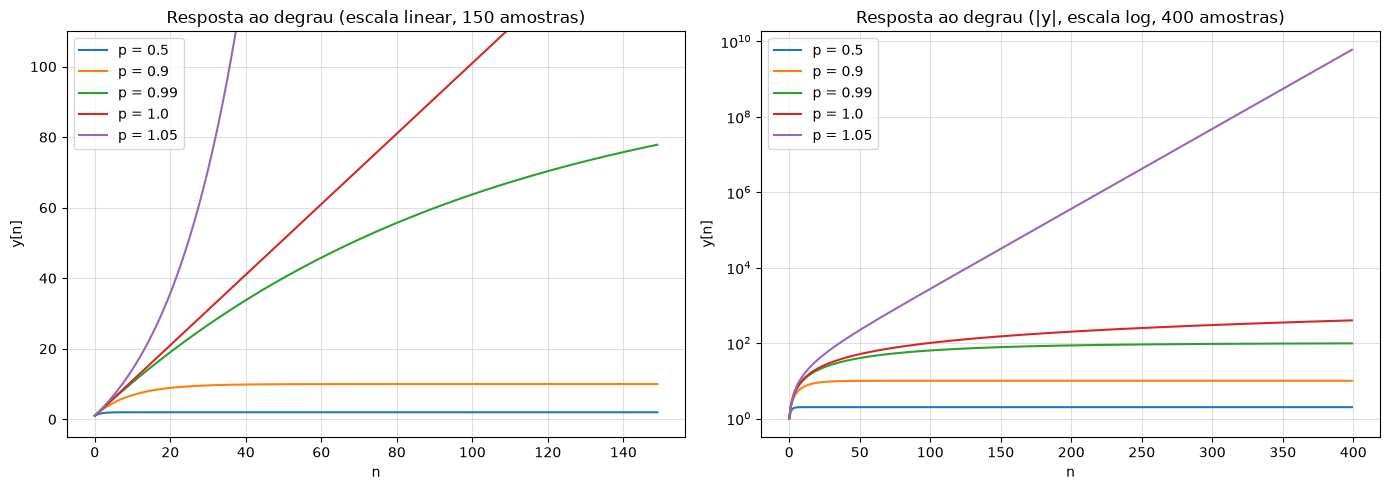

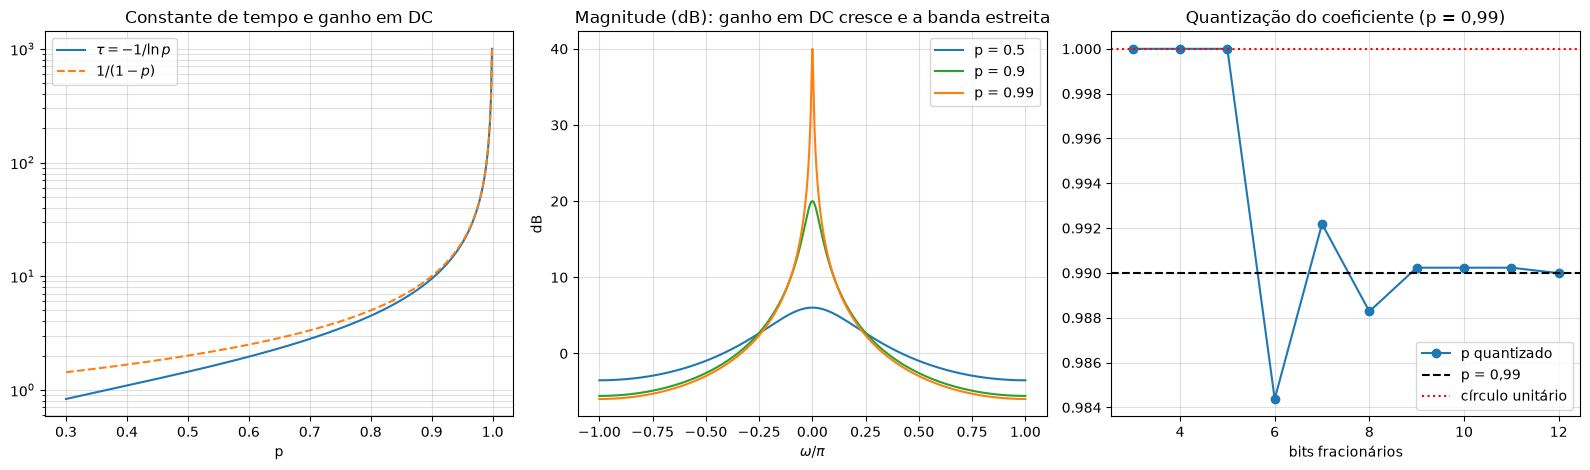


Simulação concluída!


In [1]:
"""
Roteiro de Filtros Digitais - Tópico 8: Estabilidade dos Filtros IIR

Sistema investigado: H(z) = 1 / (1 - p z^-1),  y[n] = x[n] + p y[n-1],
com polos em p1 = 0,5, p2 = 0,9, p3 = 0,99 e p4 = 1,05 (sugeridos no roteiro).
Para cada caso: polo no plano-z, resposta ao impulso h[n] = p^n u[n],
evolução temporal e classificação de estabilidade (BIBO: |p| < 1).

Complementos:
    - polo marginal (p = 1);
    - teste BIBO com entrada limitada (degrau);
    - aproximação do polo ao círculo unitário (p -> 1): constante de tempo,
      duração da resposta, soma de |h| e ganho em ω = 0;
    - sensibilidade: quantização do coeficiente p com poucos bits.
"""

import numpy as np
import matplotlib.pyplot as plt
from scipy import signal

th = np.linspace(0, 2 * np.pi, 500)
polos = [0.5, 0.9, 0.99, 1.05]
rotulos = ["p1 = 0,5", "p2 = 0,9", "p3 = 0,99", "p4 = 1,05"]
N = 600                                  # amostras da resposta ao impulso
n = np.arange(N)


def classificar(p, tol=1e-12):
    r = abs(p)
    if r < 1 - tol:
        return "ESTÁVEL"
    if r <= 1 + tol:
        return "MARGINAL"
    return "INSTÁVEL"


def resposta_impulso(p, N):
    d = np.zeros(N)
    d[0] = 1.0
    return signal.lfilter([1.0], [1.0, -p], d)


# ============================================================
# 1-2. RESPOSTA AO IMPULSO E 3-4. EVOLUÇÃO TEMPORAL
# ============================================================

print("RESPOSTA AO IMPULSO h[n] = p^n u[n]  (H(z) = 1/(1 - p z^-1))")
print("=" * 106)
print(f"{'Polo':>8}{'|p|':>7}{'classificação':>16}{'erro vs. p^n':>15}"
      f"{'h[10]':>12}{'h[100]':>12}{'h[599]':>12}{'Σ|h| (600)':>14}"
      f"{'Σ h² (energia)':>16}")
print("-" * 106)
H = {}
for p in polos:
    h = resposta_impulso(p, N)
    H[p] = h
    with np.errstate(over="ignore"):
        h_teor = p ** n.astype(float)
    err = np.max(np.abs(h - h_teor) / np.maximum(np.abs(h_teor), 1e-300))
    print(f"{p:>8}{abs(p):>7.2f}{classificar(p):>16}{err:>15.1e}"
          f"{h[10]:>12.4g}{h[100]:>12.4g}{h[-1]:>12.4g}"
          f"{np.sum(np.abs(h)):>14.5g}{np.sum(h ** 2):>16.5g}")
print("(erro relativo a p^n; Σ|h| e energia crescem sem limite quando |p| >= 1)")

print("\nEVOLUÇÃO TEMPORAL")
print("=" * 86)
print(f"{'Polo':>8}{'τ = ∓1/ln|p| (am.)':>22}{'n p/ |h|<1%':>14}"
      f"{'n p/ |h|<0,1%':>16}{'n p/ |h|>1e3':>16}{'dobra a cada (am.)':>21}")
print("-" * 86)
for p in polos:
    h = H[p]
    if abs(p) < 1:
        tau = -1 / np.log(abs(p))
        n1 = int(np.argmax(np.abs(h) < 1e-2)) if np.any(np.abs(h) < 1e-2) else None
        n01 = int(np.argmax(np.abs(h) < 1e-3)) if np.any(np.abs(h) < 1e-3) else None
        print(f"{p:>8}{tau:>22.2f}{(n1 if n1 is not None else '> 599'):>14}"
              f"{(n01 if n01 is not None else '> 599'):>16}{'—':>16}{'—':>21}")
    else:
        nov = int(np.argmax(np.abs(h) > 1e3))
        tau = 1 / np.log(abs(p))
        print(f"{p:>8}{tau:>22.2f}{'—':>14}{'—':>16}{nov:>16}"
              f"{np.log(2) * tau:>21.1f}")

# ============================================================
# POLO MARGINAL E ENTRADA LIMITADA (BIBO)
# ============================================================

casos_bibo = polos[:3] + [1.0, polos[3]]
x_deg = np.ones(N)
x_alt = np.cos(np.pi * n)           # entrada limitada alternada (±1)
print("\nTESTE BIBO: entrada limitada |x[n]| <= 1")
print("=" * 94)
print(f"{'Polo':>8}{'classificação':>16}{'max|y| degrau':>16}{'1/(1-p) (teoria)':>20}"
      f"{'max|y| entrada ±1':>20}")
print("-" * 94)
Y_deg = {}
for p in casos_bibo:
    y = signal.lfilter([1.0], [1.0, -p], x_deg)
    ya = signal.lfilter([1.0], [1.0, -p], x_alt)
    Y_deg[p] = y
    teoria = f"{1 / (1 - p):.4g}" if abs(p) < 1 else "—"
    print(f"{p:>8}{classificar(p):>16}{np.max(np.abs(y)):>16.5g}{teoria:>20}"
          f"{np.max(np.abs(ya)):>20.5g}")
print("  Estável: saída limitada para toda entrada limitada (|y| <= Σ|h| · max|x|).")
print("  p = 1: o degrau gera rampa y[n] = n+1 (ilimitada), embora h[n] = 1 seja limitada.")

# ============================================================
# RESPOSTA EM FREQUÊNCIA DOS CASOS ESTÁVEIS
# ============================================================

w = np.linspace(-np.pi, np.pi, 4001)
print("\nRESPOSTA EM FREQUÊNCIA (|H(e^{jω})| = 1/|1 - p e^{-jω}|)")
print("=" * 70)
print(f"{'Polo':>8}{'|H(0)|':>12}{'1/(1-p)':>12}{'|H(π)|':>12}{'corte -3 dB (rad)':>20}")
print("-" * 70)
for p in polos[:3]:
    _, Hf = signal.freqz([1.0], [1.0, -p], worN=w)
    mag = np.abs(Hf)
    pos = w >= 0
    i = np.argmax((mag < mag[np.argmin(np.abs(w))] / np.sqrt(2)) & pos)
    print(f"{p:>8}{mag[np.argmin(np.abs(w))]:>12.3f}{1 / (1 - p):>12.3f}"
          f"{mag[0]:>12.4f}{w[i]:>20.4f}")
print(f"  p4 = {polos[3]}: |H(e^jω)| existe numericamente, mas a DTFT de h[n] "
      "causal não converge (círculo unitário fora da ROC |z| > 1,05).")

# ============================================================
# APROXIMAÇÃO DO POLO AO CÍRCULO UNITÁRIO
# ============================================================

print("\nPOLO SE APROXIMANDO DO CÍRCULO UNITÁRIO (p -> 1)")
print("=" * 98)
print(f"{'p':>8}{'τ (amostras)':>16}{'n p/ |h|<1%':>14}{'Σ|h| = 1/(1-p)':>18}"
      f"{'|H(0)|':>10}{'banda -3 dB (rad)':>20}{'1-p':>10}")
print("-" * 98)
ps_sweep = [0.5, 0.8, 0.9, 0.95, 0.99, 0.995, 0.999]
for p in ps_sweep:
    tau = -1 / np.log(p)
    n1 = int(np.ceil(np.log(1e-2) / np.log(p)))
    wc = np.arccos(1 - (1 - p) ** 2 / (2 * p))
    print(f"{p:>8}{tau:>16.2f}{n1:>14}{1 / (1 - p):>18.2f}{1 / (1 - p):>10.1f}"
          f"{wc:>20.5f}{1 - p:>10.3f}")
print("  Ao se aproximar de |p| = 1: resposta mais lenta (τ ≈ 1/(1-p)), "
      "ganho em DC e Σ|h| crescem como 1/(1-p),\n"
      "  e a banda passante se estreita (≈ (1-p)): maior seletividade, "
      "menor margem de estabilidade.")

# ============================================================
# SENSIBILIDADE: QUANTIZAÇÃO DO COEFICIENTE
# ============================================================

print("\nQUANTIZAÇÃO DO COEFICIENTE p = 0,99 (arredondamento para b bits fracionários)")
print("=" * 86)
print(f"{'bits':>6}{'p quantizado':>16}{'erro':>12}{'classificação':>16}"
      f"{'τ (am.)':>12}{'τ original':>14}")
print("-" * 86)
tau0 = -1 / np.log(0.99)
for b in [3, 4, 5, 6, 7, 8, 10, 12]:
    pq = np.round(0.99 * 2 ** b) / 2 ** b
    cls = classificar(pq)
    tau = (-1 / np.log(pq)) if pq < 1 else np.inf
    tau_txt = f"{tau:.1f}" if np.isfinite(tau) else "∞"
    print(f"{b:>6}{pq:>16.6f}{pq - 0.99:>12.4f}{cls:>16}{tau_txt:>12}{tau0:>14.1f}")
print("  Polos próximos de |z| = 1 são sensíveis à precisão dos coeficientes: "
      "poucos bits podem levar o polo para fora do círculo ou sobre ele.")

# ============================================================
# FIGURAS
# ============================================================

cores = ["C0", "C2", "C1", "C3"]

# Fig. 1: polos no plano-z
fig, ax = plt.subplots(figsize=(8, 8))
ax.plot(np.cos(th), np.sin(th), "k--", linewidth=1.2, label="|z| = 1")
ax.fill(np.cos(th), np.sin(th), color="green", alpha=0.06)
for p, rot, cor in zip(polos, rotulos, cores):
    ax.plot(p, 0, "x", markersize=13, markeredgewidth=2.5, color=cor,
            label=f"{rot} ({classificar(p).lower()})")
ax.plot(0, 0, "o", markerfacecolor="none", color="gray", label="Zero em z = 0")
ax.set_aspect("equal")
ax.set_xlim(-1.3, 1.3)
ax.set_ylim(-1.3, 1.3)
ax.axhline(0, color="k", linewidth=0.4)
ax.axvline(0, color="k", linewidth=0.4)
ax.set_xlabel("Re(z)")
ax.set_ylabel("Im(z)")
ax.set_title("Polos no plano-z: dentro (estável) e fora (instável) do círculo unitário")
ax.legend(loc="upper left", fontsize=9)
ax.grid(True)
plt.tight_layout()
plt.show()

# Fig. 2: resposta ao impulso (cada caso com janela adequada)
fig, eixos = plt.subplots(2, 2, figsize=(13, 8))
janelas = {0.5: 25, 0.9: 60, 0.99: 400, 1.05: 100}
for ax, p, rot, cor in zip(eixos.ravel(), polos, rotulos, cores):
    L = janelas[p]
    ax.stem(n[:L], H[p][:L], basefmt=" ", linefmt=cor, markerfmt=cor + "o")
    ax.set_title(f"{rot}: {classificar(p).lower()}")
    ax.set_xlabel("n")
    ax.set_ylabel("h[n]")
    ax.grid(True)
plt.suptitle("Resposta ao impulso h[n] = pⁿ u[n] (janelas de tempo diferentes)")
plt.tight_layout()
plt.show()

# Fig. 3: |h[n]| em escala logarítmica (reta de inclinação ln|p|)
fig, ax = plt.subplots(figsize=(11, 5.5))
for p, rot, cor in zip(polos, rotulos, cores):
    ax.semilogy(n[:400], np.abs(H[p][:400]), color=cor, label=rot)
ax.axhline(1, color="k", linestyle=":", linewidth=1)
ax.set_xlabel("n (amostras)")
ax.set_ylabel(r"$|h[n]|$ (escala log)")
ax.set_title("Evolução temporal: decaimento (|p| < 1) ou crescimento (|p| > 1) exponencial")
ax.set_ylim(1e-12, 1e8)
ax.legend()
ax.grid(True, which="both", alpha=0.4)
plt.tight_layout()
plt.show()

# Fig. 4: saída para entrada limitada (degrau)
fig, eixos = plt.subplots(1, 2, figsize=(14, 5))
for p in casos_bibo:
    lab = f"p = {p}"
    eixos[0].plot(n[:150], Y_deg[p][:150], label=lab)
    eixos[1].semilogy(n[:400], np.maximum(np.abs(Y_deg[p][:400]), 1e-3), label=lab)
eixos[0].set_ylim(-5, 110)
eixos[0].set_title("Resposta ao degrau (escala linear, 150 amostras)")
eixos[1].set_title("Resposta ao degrau (|y|, escala log, 400 amostras)")
for ax in eixos:
    ax.set_xlabel("n")
    ax.set_ylabel("y[n]")
    ax.grid(True, which="both", alpha=0.4)
    ax.legend()
plt.tight_layout()
plt.show()

# Fig. 5: aproximação do círculo unitário
ps = np.linspace(0.3, 0.999, 400)
fig, eixos = plt.subplots(1, 3, figsize=(16, 4.8))
eixos[0].semilogy(ps, -1 / np.log(ps), label=r"$\tau=-1/\ln p$")
eixos[0].semilogy(ps, 1 / (1 - ps), "--", label=r"$1/(1-p)$")
eixos[0].set_title("Constante de tempo e ganho em DC")
eixos[0].set_xlabel("p")
eixos[0].legend()
for p, cor in zip(polos[:3], cores):
    _, Hf = signal.freqz([1.0], [1.0, -p], worN=w)
    eixos[1].plot(w / np.pi, 20 * np.log10(np.abs(Hf)), color=cor, label=f"p = {p}")
eixos[1].set_title("Magnitude (dB): ganho em DC cresce e a banda estreita")
eixos[1].set_xlabel(r"$\omega/\pi$")
eixos[1].set_ylabel("dB")
eixos[1].legend()
bits = np.arange(3, 13)
pq = np.round(0.99 * 2.0 ** bits) / 2.0 ** bits
eixos[2].plot(bits, pq, "o-", label="p quantizado")
eixos[2].axhline(0.99, color="k", linestyle="--", label="p = 0,99")
eixos[2].axhline(1.0, color="r", linestyle=":", label="círculo unitário")
eixos[2].set_title("Quantização do coeficiente (p = 0,99)")
eixos[2].set_xlabel("bits fracionários")
eixos[2].legend()
for ax in eixos:
    ax.grid(True, which="both", alpha=0.4)
plt.tight_layout()
plt.show()

print("\nSimulação concluída!")